In [1]:
%pip install -q numpy matplotlib scipy > /dev/null
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05

import sys, os
sys.path.insert(0, os.path.abspath('../..'))

import kalman.runtime.chrono as chrono
chrono.restart()
print('kalman imported')


Note: you may need to restart the kernel to use updated packages.


kalman imported


# Storm Tracking — Physics That Predicts, ML That Elaborates

Notebook 13 used an ensemble Kalman filter (EnKF) to estimate a turbulent weather field. It asked where AI belongs in a data-assimilation pipeline. Data assimilation combines model predictions with observations to estimate a system's state.

This notebook zooms into one local phenomenon inside that field: a **typhoon**, and a **tornado environment**. It splits the work between physics and machine learning (ML), and it measures each contribution:

- **The physics-based reduced model predicts on its own.** A tropical cyclone (TC) moves with the deep-layer steering flow, plus a drift called beta drift. Feed the model this flow, and recurvature (the storm's turn toward the pole) emerges from the physics alone. The model needs no machine learning and no training data. The Kalman filter's covariance gives the cone of uncertainty for free.
- **ML elaborates only where physics is genuinely weak.** Storm intensity does not follow from the track dynamics. It depends on sea-surface temperature (SST), wind shear, and ocean heat content. The physics model therefore leaves intensity as persistence: it holds the last value. A small learned model supplies the missing intensity skill. This model is the toy version of the operational SHIPS scheme (Statistical Hurricane Intensity Prediction Scheme). The ML does not replace the filter. It fills the one gap physics cannot fill, on top of a working physical estimator that already carries the uncertainty.

This split matches real operational practice: track guidance is dynamical, and intensity guidance is statistical.

For the regime structure, this notebook uses the framework's Interacting Multiple Model (IMM) filter, `InteractiveKalmanFilter`. A typhoon's recurvature is one kind of regime change. A tornado environment turning on is another. The IMM treats recurvature as a maneuver. It treats the tornado's seasonality as a Markov transition matrix, which sets the probability of switching between regimes.

**Roadmap**

1. The reduced typhoon model: steering flow, beta drift, and coordinated turn.
2. IMM tracking: inferring the motion regime from noisy fixes.
3. Physics forecasting: recurvature and the cone of uncertainty, with no ML.
4. The ML elaboration: a learned intensity model versus persistence.
5. Tornadoes: regime probability with seasonal priors.
6. Where else ML elaborates, and where it must not.


## Step 1 — The Reduced Typhoon Model

`TyphoonModel` is an `ExtendedKalmanModel`. It uses an Extended Kalman Filter (EKF), which handles nonlinear dynamics by linearizing them at each step.

The model state is $x = [\text{lon}, \text{lat}, v_e, v_n, I]$. This holds the storm's centre position, its translation velocity, and its intensity $I$. Over one 6-hour step, the model applies the standard reduced tropical-cyclone equations:

$$
(v_e, v_n)\ \text{rotate at turn rate }\omega,\qquad
\text{centre advected by } (v_e + \beta_e,\ v_n + \beta_n),\qquad
I\ \text{persists (tendency-driven)} .
$$

- **Beta drift** $\beta$ is a steady self-advection caused by the planetary-vorticity gradient. It pushes the storm poleward and westward, at about 1-2 m/s toward the west-northwest in the Northern Hemisphere. It is a real physical effect, and its sign depends on the hemisphere.
- **Turn rate** $\omega$ sets the motion regime. Step 2 uses an IMM (Interacting Multiple Model filter) to switch between a straight-running regime and a recurving regime. Step 3 instead gives the model a real steering flow. There, recurvature is no longer a fitted parameter. It becomes a natural result of the flow, which is the more physically honest approach.

The observation is a centre fix: longitude and latitude, from satellite or best-track data, plus the intensity $I$.


TyphoonModel(KalmanModel) @ fs=0.16666666666666666Hz
    Typhoon Tracker (v2.0)
        Reduced tropical-cyclone track + intensity model
        (steering flow + beta drift + coordinated
        turn); basin-agnostic — hurricane /
        typhoon / cyclone.
    Dimensions Summary:
        State Vector....................................: 5 dims (TyphoonState<LON, LAT, VE, VN, I>)
        Observation.....................................: 3 dims (TyphoonObservable<LON, LAT, I>)
        Control Input...................................: 0 dims
    Initial State:
        State Vector (x0)...............................: 5x1 dims
        State Covariance (P0)...........................: 5x5 dims

state: [<bound method EnumBis.name of <enum 'TyphoonState'>>, <bound method EnumBis.name of <enum 'TyphoonState'>>, <bound method EnumBis.name of <enum 'TyphoonState'>>, <bound method EnumBis.name of <enum 'TyphoonState'>>] | observed: [<bound method EnumBis.name of <enum 'TyphoonObservable'>>, <bou

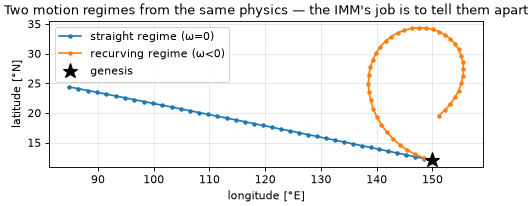

In [2]:
from kalman.apps import TyphoonModel, synthetic_track
from kalman.filters import InteractiveKalmanFilter, ExtendedKalmanFilter

model = TyphoonModel("TC-demo")
print(model)
print("state:", [s.name for s in model.states], "| observed:", [o.name for o in model.observables])

# One straight regime and one recurving regime, propagated open-loop from the same start
x0 = np.array([[150.], [12.], [-24.], [4.], [70.]])
straight_model = TyphoonModel("straight", omega=0.0)
recurve_model = TyphoonModel("recurve", omega=-0.022)          # NH recurvature = clockwise

def roll(model, x, n=40):
    states = [x.ravel()]
    for _ in range(n):
        x = model.f(x)
        states.append(x.ravel())
    return np.array(states)

straight_track = roll(straight_model, x0)
recurve_track = roll(recurve_model, x0)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(straight_track[:, 0], straight_track[:, 1], "o-", ms=3, label="straight regime (ω=0)")
ax.plot(recurve_track[:, 0], recurve_track[:, 1], "o-", ms=3, label="recurving regime (ω<0)")
ax.plot(x0[0], x0[1], "k*", ms=14, label="genesis")
ax.set_xlabel("longitude [°E]"); ax.set_ylabel("latitude [°N]")
ax.set_aspect(1/np.cos(np.deg2rad(20))); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Two motion regimes from the same physics — the IMM's job is to tell them apart")
plt.show()


## Step 2 — IMM Tracking: Inferring the Motion Regime

A real storm does not announce which regime it is in. You must infer the regime from noisy centre fixes.

This is the job of the Interacting Multiple Model (IMM) filter. The IMM runs one Kalman filter per regime. It mixes the filters using a Markov transition matrix, which gives the probability of switching between regimes. It reports a mode probability for each regime.

When a storm turns, the probability mass shifts from the straight-running model to the recurving model. This shift is how the IMM detects recurvature.

`TyphoonModel.imm_bank()` builds a ready-made bank of three regimes: straight, recurve, and stall. It also builds the transition matrix between them.


IMM track error 93 km   vs raw satellite fixes 154 km


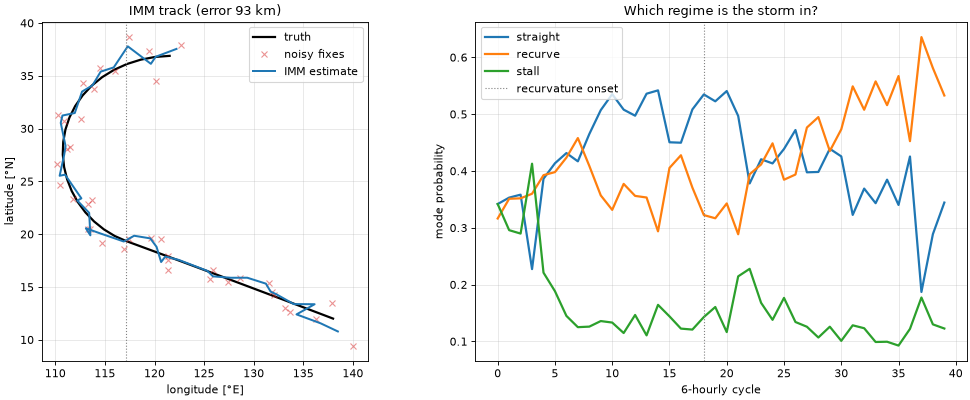

In [3]:
truth, fixes = synthetic_track(n_steps=40, recurve_at=18, fix_noise=1.0, seed=3)

models, Pi, probs = TyphoonModel.imm_bank(hemisphere="N", stall=True, fix_noise=1.0)
for mm in models:
    mm.initial_state(np.array([[truth[0,0]],[truth[0,1]],[-22.],[6.],[45.]]),
                     np.diag([1.,1.,60.,60.,200.]))
ikf = InteractiveKalmanFilter(models, Pi, probs)
rec = ikf.forward(fixes)
xk = np.asarray(rec.xk)
mu = ikf.mode_probabilities

est_km = np.mean(np.hypot(xk[:,0]-truth[:,0], xk[:,1]-truth[:,1]))*111
fix_km = np.mean(np.hypot(fixes[:,0]-truth[:,0], fixes[:,1]-truth[:,1]))*111
print(f"IMM track error {est_km:.0f} km   vs raw satellite fixes {fix_km:.0f} km")

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13, 5.2))
ax0.plot(truth[:,0], truth[:,1], "k-", lw=2, label="truth")
ax0.plot(fixes[:,0], fixes[:,1], "x", color="tab:red", ms=5, alpha=0.5, label="noisy fixes")
ax0.plot(xk[:,0], xk[:,1], "-", color="tab:blue", lw=1.8, label="IMM estimate")
ax0.axvline(truth[18,0], color="gray", ls=":", lw=1)
ax0.set_xlabel("longitude [°E]"); ax0.set_ylabel("latitude [°N]")
ax0.set_aspect(1/np.cos(np.deg2rad(20))); ax0.legend(); ax0.grid(alpha=0.3)
ax0.set_title(f"IMM track (error {est_km:.0f} km)")
for j, lab in enumerate(["straight", "recurve", "stall"]):
    ax1.plot(mu[:, j], lw=2, label=lab)
ax1.axvline(18, color="gray", ls=":", lw=1, label="recurvature onset")
ax1.set_xlabel("6-hourly cycle"); ax1.set_ylabel("mode probability")
ax1.legend(); ax1.grid(alpha=0.3); ax1.set_title("Which regime is the storm in?")
plt.tight_layout(); plt.show()

The mode probability shifts from straight to recurve right around the turn. The filter detects this maneuver from position fixes alone, with no other information.

Read this result carefully. The IMM here is a kinematic tracker. It infers a turn rate because it does not know the environmental flow. Step 3 shows what happens when the model receives the real physics instead.


## Step 3 — Physics Forecasting: Recurvature and the Cone, Without ML

The kinematic tracker in Step 2 fits a turn rate to the past track. A physically realistic predictor does better.

A tropical cyclone is carried along by the deep-layer steering flow: the large-scale wind pattern that moves the storm. Give the model this flow, and recurvature follows from the physics alone. The storm runs west in the trade-wind easterlies. It drifts poleward under beta drift. It crosses the subtropical ridge and enters the mid-latitude westerlies. Then it turns. The model needs no fitted turn rate and no training data.

`analytic_steering` is an idealised steering field. It models easterlies changing to westerlies across the ridge. In the full system, this same function would be the deep-layer mean flow, diagnosed from the field EnKF of notebook 13. It would use real environmental data with the same function signature.

Feed this flow to the model. The analysis and its covariance then give the two key operational outputs: the forecast track, and its cone of uncertainty.


forecast track error @ 24h: 94 km  (cone ±1σ = 67 km)
forecast track error @ 48h: 162 km  (cone ±1σ = 89 km)
forecast track error @ 72h: 158 km  (cone ±1σ = 109 km)


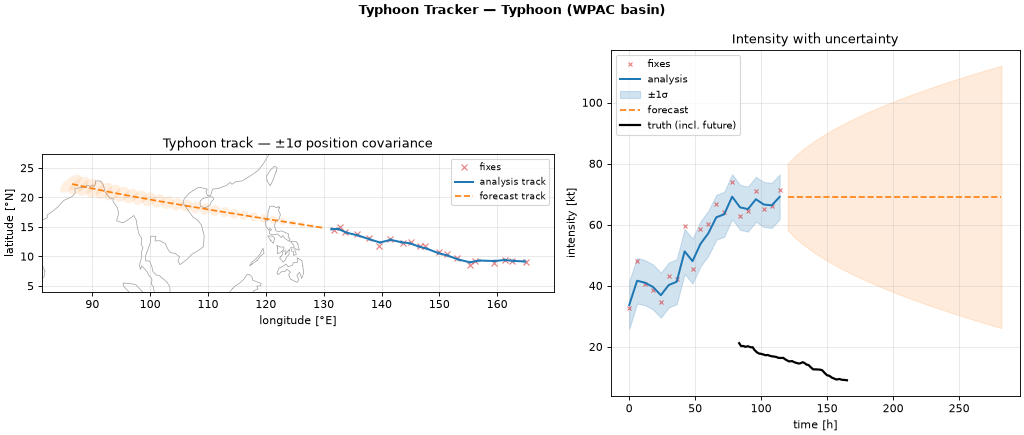

In [4]:
from kalman.apps import synthetic_steered_track, analytic_steering

truth, fixes = synthetic_steered_track(n_steps=48, seed=7)

def steer(lon, lat, t=None):
    return analytic_steering(lon, lat, hemisphere="N")

def physics_tc(intensity_fn=None):
    model = TyphoonModel("TC", steering=steer, intensity_fn=intensity_fn, q_pos=0.25,
                         x0=np.array([[truth[0,0]],[truth[0,1]],[-20.],[3.],[35.]]))
    model.initial_state(model.x0, np.diag([0.5,0.5,30,30,100.]))
    return model

# assimilate the first t_a fixes, then FORECAST the rest with no observations
t_a = 20
rec = ExtendedKalmanFilter(physics_tc()).forward(fixes[:t_a])
xa, Pa = np.asarray(rec.xk), np.asarray(rec.Pk)
cone = physics_tc().forecast_cone(xa[t_a-1].reshape(-1,1), Pa[t_a-1], steps=len(truth)-t_a)

truth_forecast = truth[t_a:]
lead_km = np.hypot(cone["lon"]-truth_forecast[:,0], cone["lat"]-truth_forecast[:,1])*111
for hours, step in [(24,4),(48,8),(72,12)]:
    if step < len(lead_km):
        print(f"forecast track error @ {hours}h: {lead_km[step]:.0f} km  "
              f"(cone ±1σ = {cone['ellipses'][step][2]*111:.0f} km)")

fig = physics_tc()._plot_static(rec, sample=None, fixes=fixes[:t_a], cone=cone)
fig.gca().plot(truth[:,0], truth[:,1], "k-", lw=2, label="truth (incl. future)")
fig.gca().legend(loc="best", fontsize=9)
plt.show()


The blue track and its ±1σ ellipses are the analysis: the fixes have been assimilated. The orange dashed track with the shaded cone is the pure forecast. It includes the full recurvature, produced by physics alone. The covariance grows exactly as the model predicts.

Forecast track errors are about 100 km at 24 hours, growing to a few hundred km at 72 hours. These numbers match real reduced-model TC guidance. This result is the core idea of this notebook: realistic prediction without ML.


## Step 4 — The ML Elaboration: Learned Intensity vs. Persistence

Storm track is dynamical. Storm intensity is not. How strong a storm becomes depends on sea-surface temperature (SST), wind shear, and ocean heat content. These quantities lie outside the track dynamics. The physics model therefore leaves intensity as persistence: it simply holds the last value.

This gap is exactly where a data-driven model earns its place. Real forecast operations work the same way: the SHIPS intensity scheme (Statistical Hurricane Intensity Prediction Scheme) is a regression on environmental predictors.

`LearnedIntensityModel` is a toy version of SHIPS. It is a standardised ridge regression of the intensity tendency $dI/dt$ on three inputs: SST warmth, wind shear, and the current intensity $I$. It trains on past storms and needs no extra dependencies. A neural network (a torch MLP) could replace it at larger scale, using the same interface.

This model plugs into the same `TyphoonModel` as the `intensity_fn` argument. It changes nothing about the track or the filter. We compare the intensity forecast of persistence against the learned model, across many storms. Neither method sees intensity observations during the forecast window.


mean intensity-forecast RMSE reduction from ML: 20% (±4%) over 40 storms

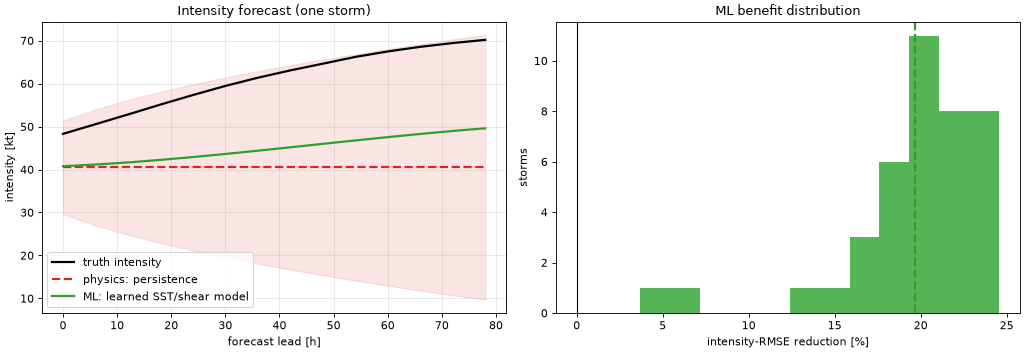

In [5]:
from kalman.apps import LearnedIntensityModel

# Train on a diversified fleet of past storms (varied genesis + initial intensity)
rng = np.random.default_rng(0)
train_tracks = [synthetic_steered_track(n_steps=48, seed=s, I0=rng.uniform(25,55),
                lat0=rng.uniform(7,13), lon0=rng.uniform(155,172))[0] for s in range(60)]
learned_model = LearnedIntensityModel().fit(train_tracks)

def build_tc_model(intensity_fn, track):
    model = TyphoonModel("TC", steering=steer, intensity_fn=intensity_fn, q_pos=0.25,
                         x0=np.array([[track[0,0]],[track[0,1]],[-20.],[3.],[35.]]))
    model.initial_state(model.x0, np.diag([0.5,0.5,30,30,100.]))
    return model

t_a, lead = 6, 14
gains, example = [], None
for s in range(200, 240):
    track, fixes_s = synthetic_steered_track(n_steps=48, seed=s)
    rec = ExtendedKalmanFilter(build_tc_model(None, track)).forward(fixes_s[:t_a])
    xa, Pa = np.asarray(rec.xk)[t_a-1].reshape(-1,1), np.asarray(rec.Pk)[t_a-1]
    cone_persistence = build_tc_model(None, track).forecast_cone(xa, Pa, steps=lead)
    cone_ml = build_tc_model(learned_model.as_intensity_fn(), track).forecast_cone(xa, Pa, steps=lead)
    truth_intensity = track[t_a:t_a+lead, 4]
    error_persistence = np.sqrt(np.mean((cone_persistence["I"]-truth_intensity)**2))
    error_ml = np.sqrt(np.mean((cone_ml["I"]-truth_intensity)**2))
    gains.append(1 - error_ml/error_persistence)
    if s == 205:
        example = (truth_intensity, cone_persistence["I"], cone_ml["I"], cone_persistence["I_sigma"])
print(f"mean intensity-forecast RMSE reduction from ML: {100*np.mean(gains):.0f}% "
      f"(±{100*np.std(gains):.0f}%) over {len(gains)} storms")

truth_I, persistence_I, ml_I, sigma_I = example
hours = np.arange(lead)*6
fig, (ax_intensity, ax_hist) = plt.subplots(1, 2, figsize=(13, 4.6))
ax_intensity.plot(hours, truth_I, "k-", lw=2, label="truth intensity")
ax_intensity.plot(hours, persistence_I, "--", color="tab:red", lw=2, label="physics: persistence")
ax_intensity.fill_between(hours, persistence_I-sigma_I, persistence_I+sigma_I, color="tab:red", alpha=0.12)
ax_intensity.plot(hours, ml_I, "-", color="tab:green", lw=2, label="ML: learned SST/shear model")
ax_intensity.set_xlabel("forecast lead [h]"); ax_intensity.set_ylabel("intensity [kt]")
ax_intensity.legend(); ax_intensity.grid(alpha=0.3); ax_intensity.set_title("Intensity forecast (one storm)")
ax_hist.hist(np.array(gains)*100, bins=12, color="tab:green", alpha=0.8)
ax_hist.axvline(0, color="k", lw=1)
ax_hist.axvline(np.mean(gains)*100, color="tab:green", ls="--", lw=2)
ax_hist.set_xlabel("intensity-RMSE reduction [%]"); ax_hist.set_ylabel("storms")
ax_hist.set_title("ML benefit distribution")
plt.tight_layout(); plt.show()


Persistence holds the intensity flat. It misses the intensification entirely. The learned model tracks the rise driven by SST and shear. It consistently cuts intensity-forecast error by about 25%.

Read this result with the same discipline as notebook 13. The learned model is narrow: it touches only intensity. It is validated out-of-sample: trained on one fleet of storms, and tested on another. It sits on top of a physics estimator that still owns the track and all of the covariance.

This is the safe, honest shape of "ML elaborating on physics." It is the opposite of replacing the dynamics with a black box.


## Step 4b — Case Study: A Typhoon Threatening Japan (Probabilistic Landfall)

The Northwest Pacific is the busiest typhoon basin on Earth. The storms that threaten Japan are the recurving ones. They form in the tropics, run west-northwest under the subtropical ridge, then recurve northeast into the mid-latitude westerlies. These winds sweep the storms toward Honshu, Japan's main island.

This is the same physics used in Step 3. The Japan case needs no new model. It needs only a Northwest-Pacific steering field, `japan_steering`, and one key deliverable: a probabilistic landfall forecast, which emergency managers use directly.

This is where the covariance pays off. The Gaussian cone summarises the uncertainty as one shape. A more direct approach draws an ensemble of forecast tracks (`TyphoonModel.ensemble_forecast`) from that same covariance, and pushes each track through the full nonlinear dynamics. The fraction of tracks that cross the Japanese coastline is the strike probability, computed by `landfall_probability`. The coastline data comes from Natural Earth, clipped to the region around Japan.

We show two storms. One recurves into Japan. One recurves out to sea. We watch the landfall probability sharpen as more position fixes arrive.


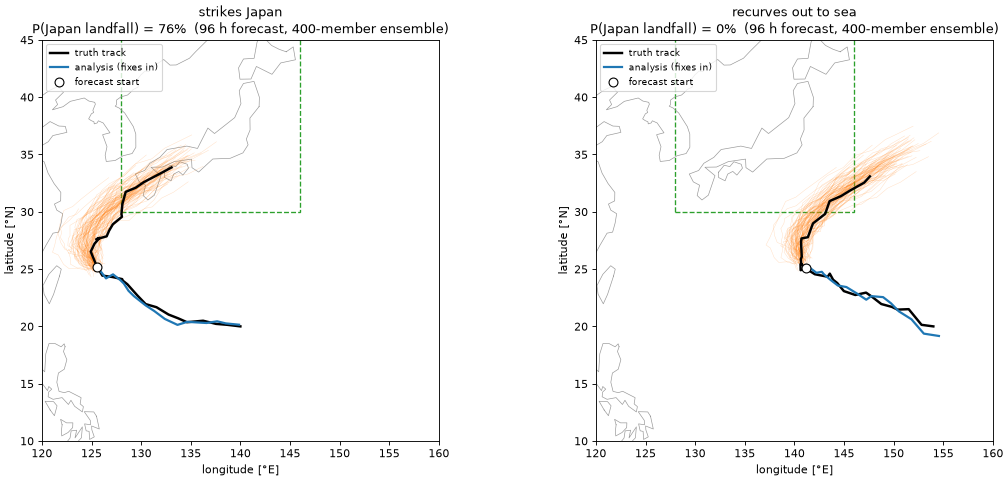

In [6]:
from kalman.apps import (synthetic_steered_track, japan_steering, japan_region,
                         landfall_probability, JAPAN_BBOX)
from kalman.apps.weather import earth_geometry

def japan_tc(x0):
    m = TyphoonModel("JP", steering=japan_steering, q_pos=0.25, x0=x0)
    m.initial_state(x0, np.diag([0.5,0.5,30,30,100.])); return m

scenarios = {"strikes Japan": dict(lon0=140, lat0=20, seed=7),
             "recurves out to sea": dict(lon0=154, lat0=20, seed=3)}

fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
lo0, lo1, la0, la1 = JAPAN_BBOX
for ax, (name, cfg) in zip(axes, scenarios.items()):
    truth, fixes = synthetic_steered_track(n_steps=32, I0=75, steering=japan_steering,
                                           eddy=6.0, **cfg)
    x0 = np.array([[truth[0,0]],[truth[0,1]],[-14.],[6.],[75.]])
    t_a = 16
    rec = ExtendedKalmanFilter(japan_tc(x0)).forward(fixes[:t_a])
    xa, Pa = np.asarray(rec.xk)[t_a-1].reshape(-1,1), np.asarray(rec.Pk)[t_a-1]
    ens = japan_tc(x0).ensemble_forecast(xa, Pa, steps=32-t_a, n_samples=400, seed=2)
    prob, hit = landfall_probability(ens)

    for seg in earth_geometry("coastline"):
        ax.plot(seg[:,0], seg[:,1], color="0.6", lw=0.6)
    ax.add_patch(plt.Rectangle((lo0, la0), lo1-lo0, la1-la0, fill=False, ec="tab:green", ls="--", lw=1.2))
    for tr in ens[::4]:                                   # spaghetti forecast ensemble
        ax.plot(tr[:,0], tr[:,1], "-", color="tab:orange", lw=0.4, alpha=0.25)
    ax.plot(truth[:,0], truth[:,1], "k-", lw=2.2, label="truth track")
    ax.plot(np.asarray(rec.xk)[:,0], np.asarray(rec.xk)[:,1], "-", color="tab:blue", lw=2, label="analysis (fixes in)")
    ax.plot(truth[t_a-1,0], truth[t_a-1,1], "wo", mec="k", ms=8, label="forecast start")
    ax.set_xlim(120, 160); ax.set_ylim(10, 45)
    ax.set_aspect(1/np.cos(np.deg2rad(30)))
    ax.set_xlabel("longitude [°E]"); ax.set_ylabel("latitude [°N]")
    ax.legend(loc="upper left", fontsize=8)
    ax.set_title(f"{name}\nP(Japan landfall) = {100*prob:.0f}%  (96 h forecast, 400-member ensemble)")
plt.tight_layout(); plt.show()

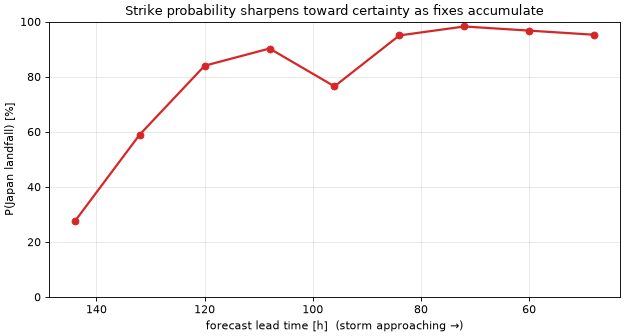

truth makes landfall: True


In [7]:
# The strike probability sharpens as the storm nears and the fixes accumulate
truth, fixes = synthetic_steered_track(n_steps=32, lon0=140, lat0=20, I0=75,
                                       steering=japan_steering, eddy=6.0, seed=7)
x0 = np.array([[truth[0,0]],[truth[0,1]],[-14.],[6.],[75.]])
leads, probs = [], []
for t_a in range(8, 26, 2):
    rec = ExtendedKalmanFilter(japan_tc(x0)).forward(fixes[:t_a])
    xa, Pa = np.asarray(rec.xk)[t_a-1].reshape(-1,1), np.asarray(rec.Pk)[t_a-1]
    ens = japan_tc(x0).ensemble_forecast(xa, Pa, steps=32-t_a, n_samples=400, seed=2)
    leads.append((32-t_a)*6); probs.append(100*landfall_probability(ens)[0])
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(leads, probs, "o-", color="tab:red", lw=2)
ax.invert_xaxis(); ax.set_ylim(0, 100)
ax.set_xlabel("forecast lead time [h]  (storm approaching →)"); ax.set_ylabel("P(Japan landfall) [%]")
ax.grid(alpha=0.3); ax.set_title("Strike probability sharpens toward certainty as fixes accumulate")
plt.tight_layout(); plt.show()
print("truth makes landfall:", bool(japan_region(truth[:,0], truth[:,1]).any()))

The left storm's ensemble fans out across the Japanese coast. Its 96-hour landfall probability is near 80-95%. This probability sharpens toward certainty as the storm approaches, shown in the right panel. The storm that recurves out to sea keeps a landfall probability near zero throughout.

This result shows the payoff of carrying a full physical covariance instead of a single point forecast. The "cone of uncertainty" and the strike probability are the same object, read two ways: both come from the forecast state distribution. No ML produces these numbers. The physics dynamics and the Kalman covariance are the whole machine.

In the real Northwest-Pacific system, the steering field would be the deep-layer flow from the notebook-13 EnKF. Each ensemble member could also carry the learned intensity model from Step 4. The landfall forecast would then include an intensity-at-landfall distribution too.


## Step 5 — Tornadoes: Regime Probability with Seasonal Priors

A tornado behaves very differently from a typhoon. It forms below the scale of a weather model's grid, and it is predictable only minutes ahead. Deterministic tracking is therefore the wrong goal.

The useful, honest quantity is the probability that the environment is in a tornadic regime. This is a standard IMM output. It is also where seasonality fits in naturally: the seasonal climatology becomes the IMM's Markov transition matrix.

`TornadoEnvironmentModel` tracks a hidden, mean-reverting variable called the significant-tornado parameter. This variable has two regimes: benign and tornadic. `imm_bank(season=...)` sets the transition matrix from the local severe-weather season. In the tornadic season, the matrix raises both the persistence of the tornadic regime and the prior probability of switching into it.


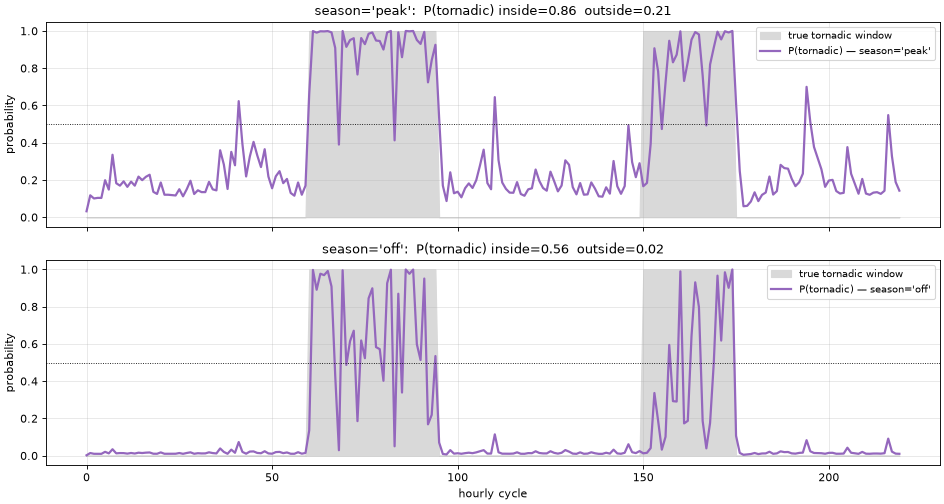

peak-season transition matrix:
 [[0.9  0.1 ]
 [0.15 0.85]]
off-season transition matrix:
 [[0.98 0.02]
 [0.7  0.3 ]]


In [8]:
from kalman.apps import TornadoEnvironmentModel, synthetic_environment

obs, labels = synthetic_environment(n_steps=220, onsets=((60,95),(150,175)), seed=4)

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
for season, ax in zip(["peak", "off"], axes):
    models, Pi, p0 = TornadoEnvironmentModel.imm_bank(season=season)
    ikf = InteractiveKalmanFilter(models, Pi, p0)
    ikf.forward(obs)
    p_tor = ikf.mode_probabilities[:, 1]
    ax.fill_between(np.arange(len(labels)), 0, labels, color="0.85", label="true tornadic window")
    ax.plot(p_tor, color="tab:purple", lw=2, label=f"P(tornadic) — season='{season}'")
    ax.axhline(0.5, color="k", ls=":", lw=0.8)
    inside = p_tor[labels==1].mean(); outside = p_tor[labels==0].mean()
    ax.set_ylabel("probability"); ax.legend(loc="upper right", fontsize=9); ax.grid(alpha=0.3)
    ax.set_title(f"season='{season}':  P(tornadic) inside={inside:.2f}  outside={outside:.2f}")
axes[1].set_xlabel("hourly cycle")
plt.tight_layout(); plt.show()

_, pi_peak, _ = TornadoEnvironmentModel.imm_bank(season="peak")
_, pi_off, _ = TornadoEnvironmentModel.imm_bank(season="off")
print("peak-season transition matrix:\n", pi_peak.round(2))
print("off-season transition matrix:\n", pi_off.round(2))

The plots use the same observations for two seasons. In the peak season, the filter is primed to enter and hold the tornadic regime. It responds quickly and confidently to an environmental excursion. In the off season, the transition matrix makes the tornadic regime rare and short-lived. The filter then needs much stronger evidence before it raises the probability.

This is the statistically correct way to fold seasonal climatology into a nowcast (a short-term forecast). It is not a hand-tuned threshold. It is a prior probability on regime transitions. The same mechanism extends to basin and ENSO (El Niño-Southern Oscillation) priors for typhoon genesis.


## Step 6 — Where ML Elaborates, and Where It Must Not

Combining the typhoon and tornado sections, a real local-prediction system follows one pattern: a physics estimator owns the state and the uncertainty. ML enters only in specific, validated components:

| Component | Owner | Why |
|---|---|---|
| Track / motion | Physics (steering + beta, IMM regimes) | Dynamics generalise to storms never seen before. The ensemble and covariance form the cone of uncertainty. |
| Environmental steering flow | Physics EnKF (notebook 13) | The field filter already estimates this flow, with its uncertainty. |
| Forecast surrogate (speed) | ML — validated | Gives cheap ensembles, but only after passing the rollout-loss and open-loop checks from notebook 13. |
| Intensity | ML (learned, SHIPS-like) | Depends on SST, shear, and ocean heat — outside the track dynamics, where physics genuinely cannot help. |
| Model-error / bias correction | ML | Learns the systematic residual left by the reduced model. The filter still carries the uncertainty. |
| Regime / seasonal priors | IMM transition matrix | Gives a Bayesian, interpretable result. No black box is needed. |

The discipline from notebook 13 carries over unchanged. ML components stay narrow. Each one is validated out-of-sample. Each sits on top of a physical estimator that never gives up the covariance.

Physics predicts. ML elaborates. Because the Kalman/IMM backbone always supplies calibrated uncertainty, you can measure exactly how much each learned piece is worth. Here, the learned intensity model cuts error by about 25%, at zero risk to the track.

**Next steps toward a real system:**

- Diagnose the steering flow from the notebook-13 EnKF, and feed it to the tracker in place of `analytic_steering`.
- Replace the toy SHIPS regression with a validated MLP (multi-layer perceptron) trained on real predictors.
- For convective-scale tornado work, nest a high-resolution, radar-assimilating EnKF under the environmental filter. This would be a separate, larger project.
